# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Holdout metrics and plots
include **`hs`, `tp`, `dir`, `spr`** (`spr` via PCA; `tp` raw). Use
`mm.report_training_data(goal, n=450)` or `mm.load_fit_summary(goal, 450)` after
fit to inspect site filter and PCA site retention.

In [1]:
import matplotlib.pyplot as plt
from utils.config import METAMODEL, load_goals, mda_max_points
from utils.evaluation import validation as val
from utils.model import metamodel as mm

In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]
metrics = METAMODEL["validation"]["metrics_variables"]
site_filter = METAMODEL["site_filter"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"metrics    : {metrics}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
for key, threshold in site_filter.items():
    if key.endswith("_max"):
        var = key[:-4]
        print(f"{var} filter : > {threshold} removed before PCA (site_filter)")
    elif key.endswith("_min"):
        var = key[:-4]
        print(f"{var} filter : < {threshold} removed before PCA (site_filter)")
print("PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
candidates : [50, 100, 150, 250, 450]
metrics    : ['hs', 'tp', 'dir', 'spr']
MDA max    : 450 (test cases = 500 - max)
hs filter : > 10.0 removed before PCA (site_filter)
tp filter : < 0.5 removed before PCA (site_filter)
PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)


## 1 · Fit

In [3]:
# All goals:
# mm.fit_all(gp_epochs=1500)

## 2 · Validate

In [4]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep(1)
metrics.head()

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,23400,3.186683e-03,5.796408e-02,0.924301,Metamodel,SnapWave
1,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,23400,9.029724e-08,7.320748e-07,1.000000,Metamodel,SnapWave
2,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,23400,6.032070e-01,1.425964e+01,0.960195,Metamodel,SnapWave
3,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,23400,4.823733e-01,8.350126e+00,0.607965,Metamodel,SnapWave
4,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,16450,3.062621e-03,6.501875e-02,0.944575,Metamodel,SnapWave


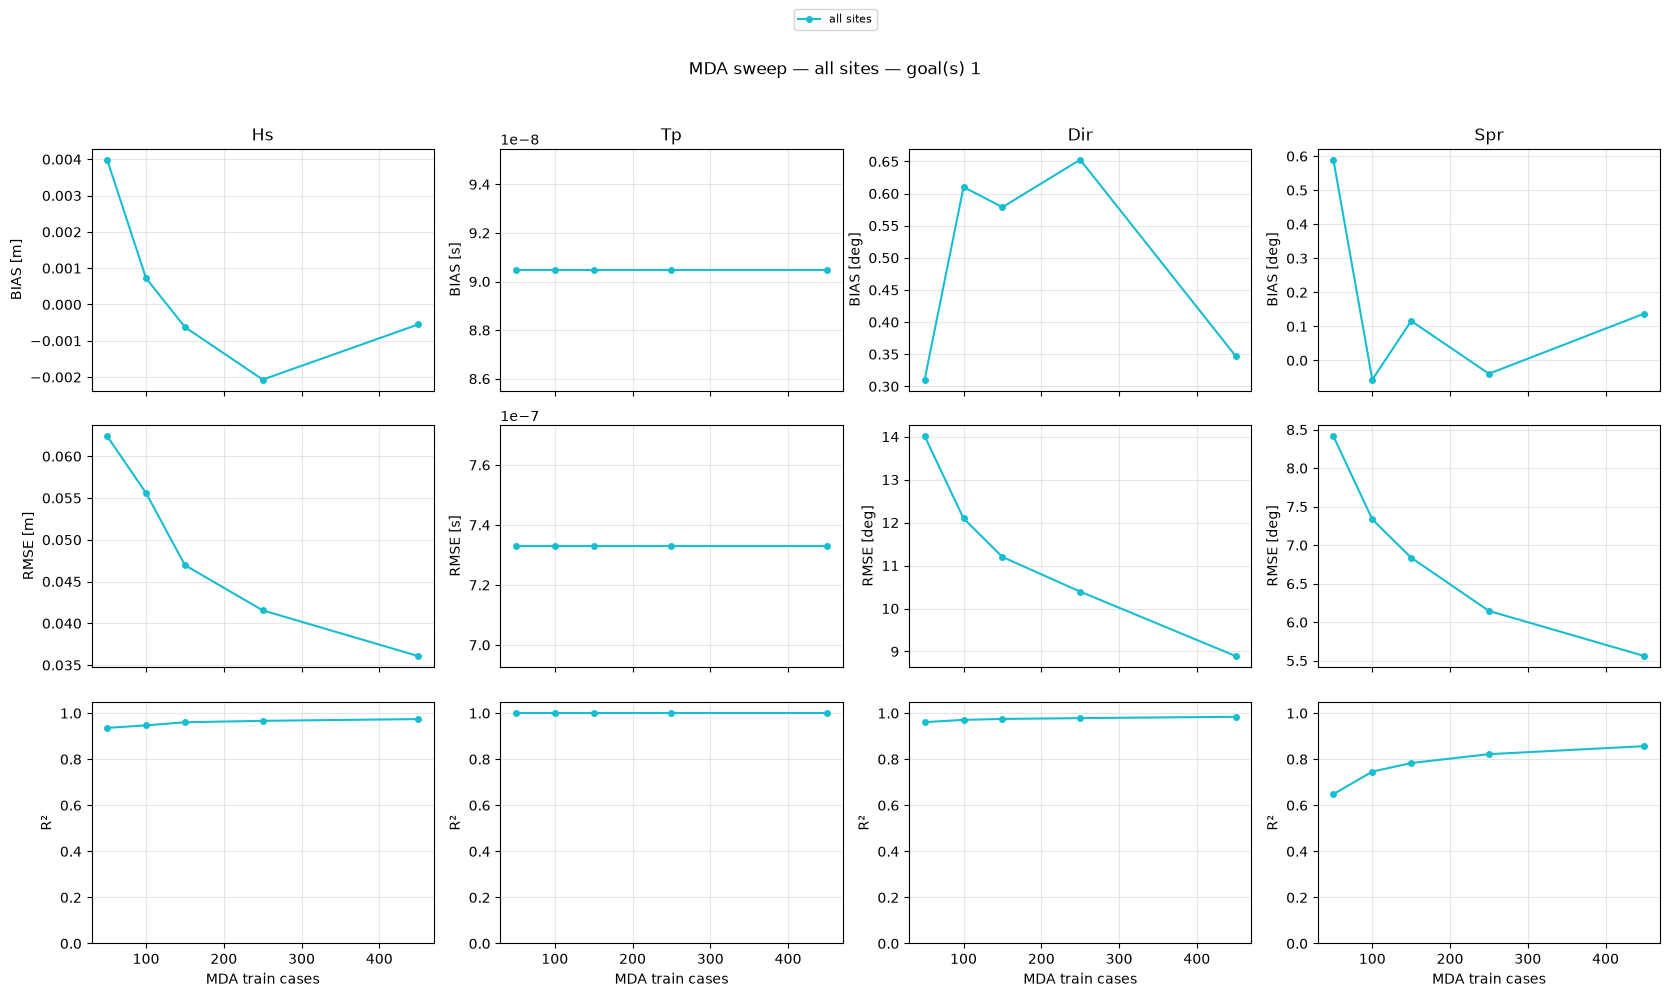

In [5]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3 · Plot

In [6]:
n = 450  # MDA size to plot
result = val.validate(1, n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

['5m',
 '10m',
 '20m',
 'buoy_AmelanderZeegat_1_1',
 'buoy_AmelanderZeegat_1_2',
 'buoy_EierlandseGat',
 'buoy_EurogeulE13',
 'buoy_IJmuidenMunitiestort_1',
 'buoy_PettenMeetraai01',
 'buoy_StortemelkWest',
 'buoy_WestereemsWest',
 'buoy_ZandmoterBoeiNoord']

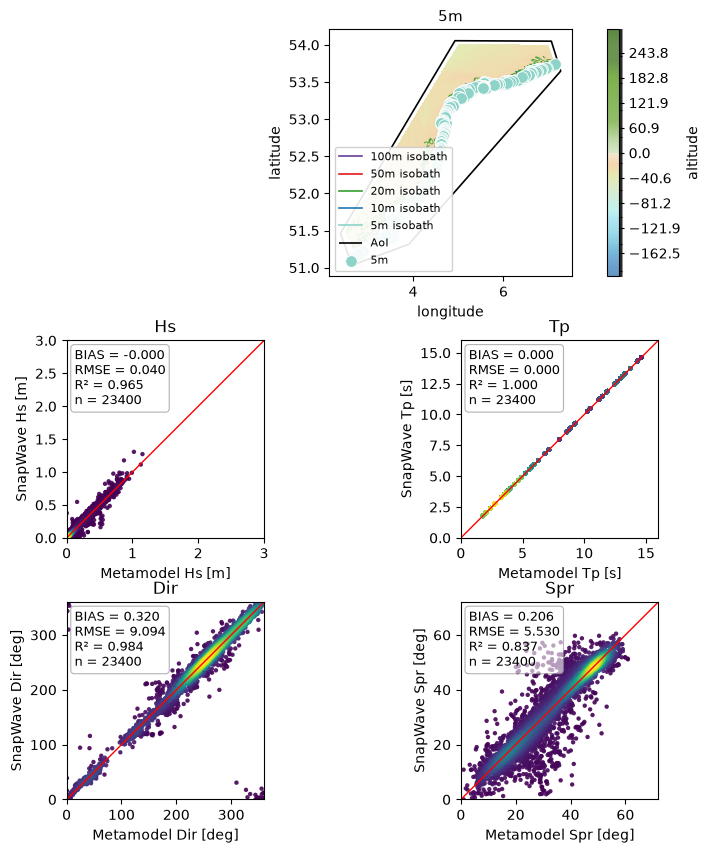

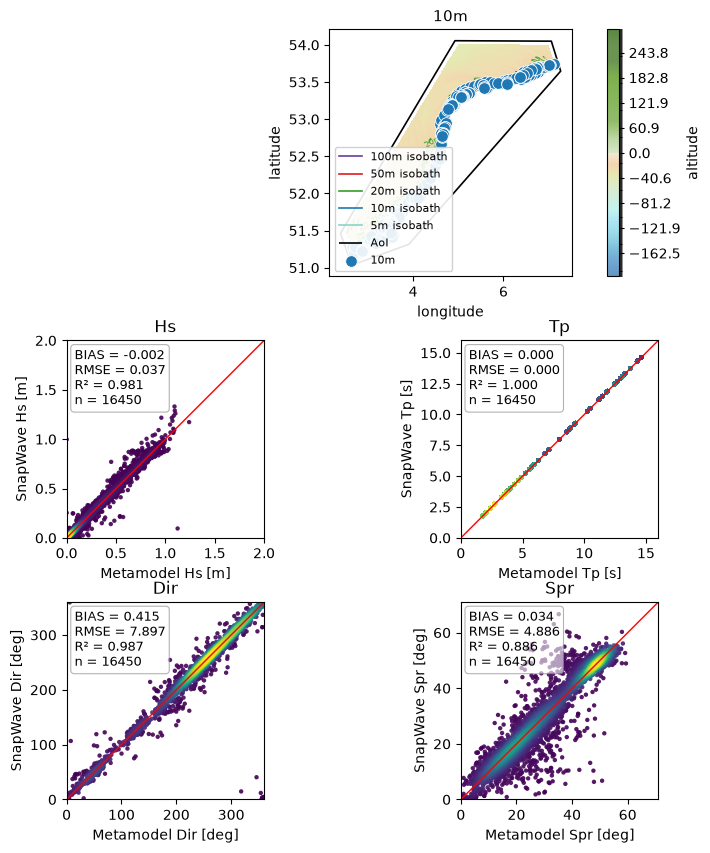

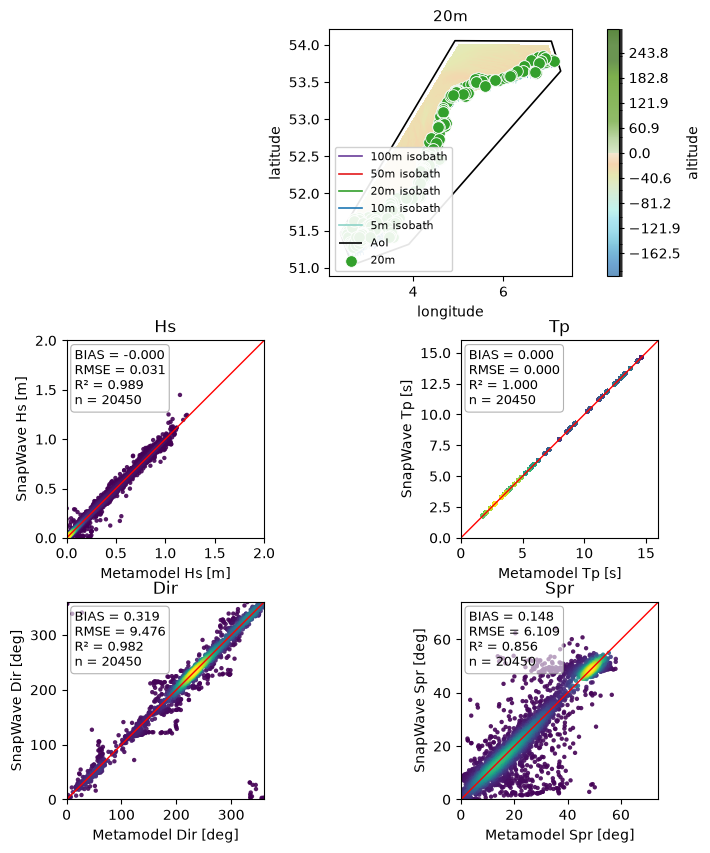

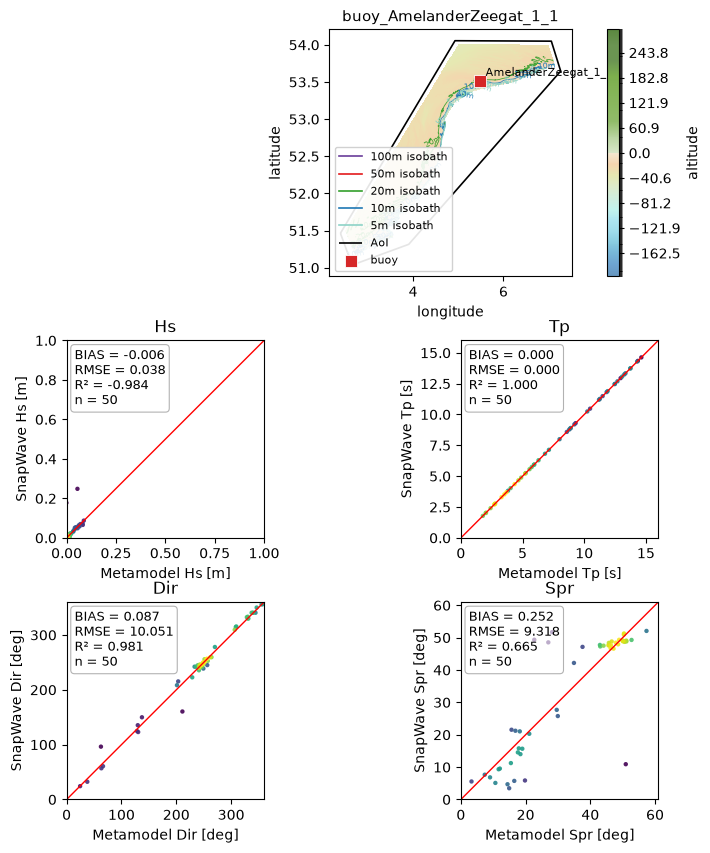

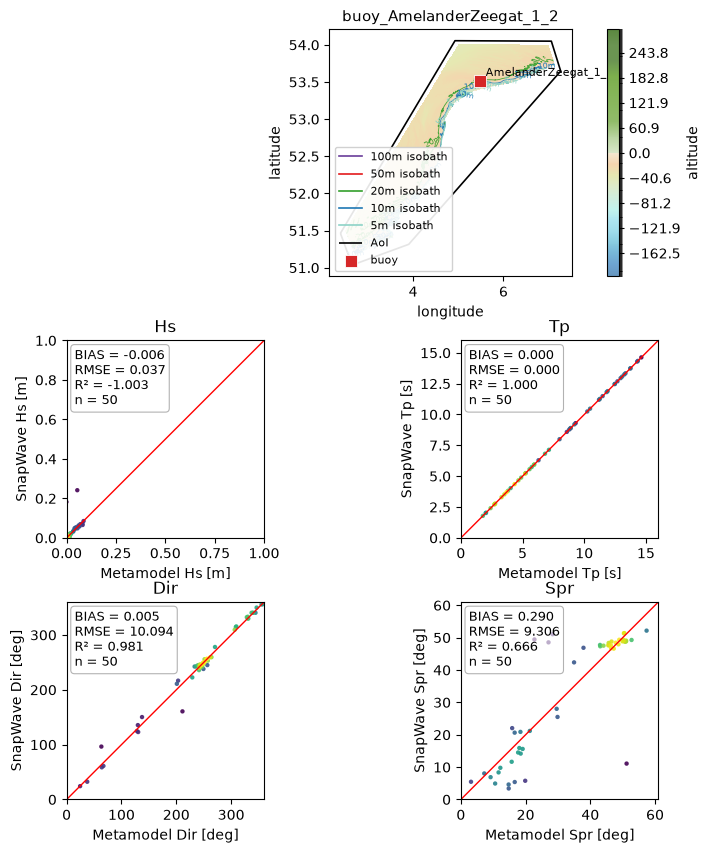

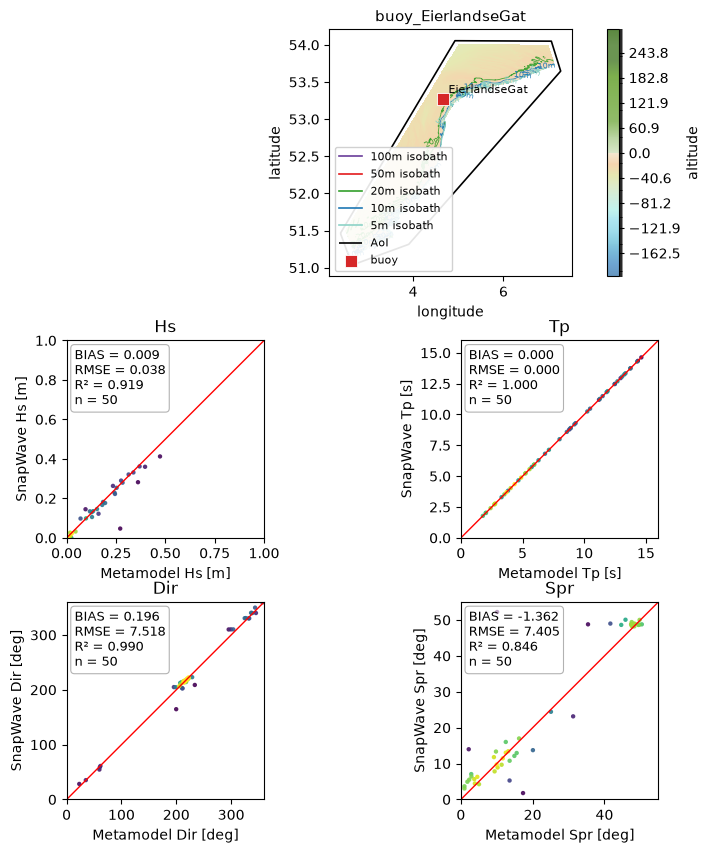

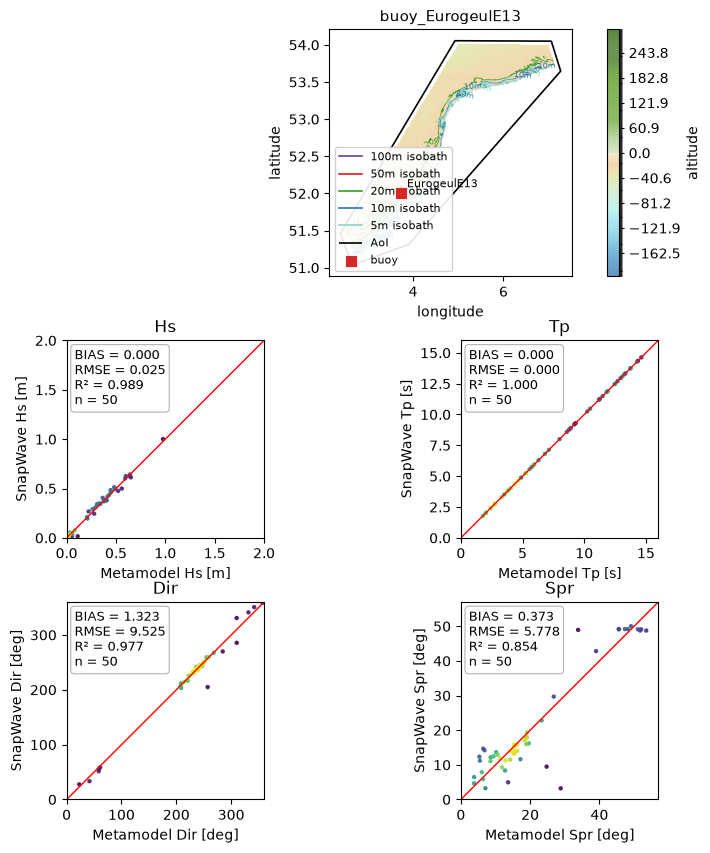

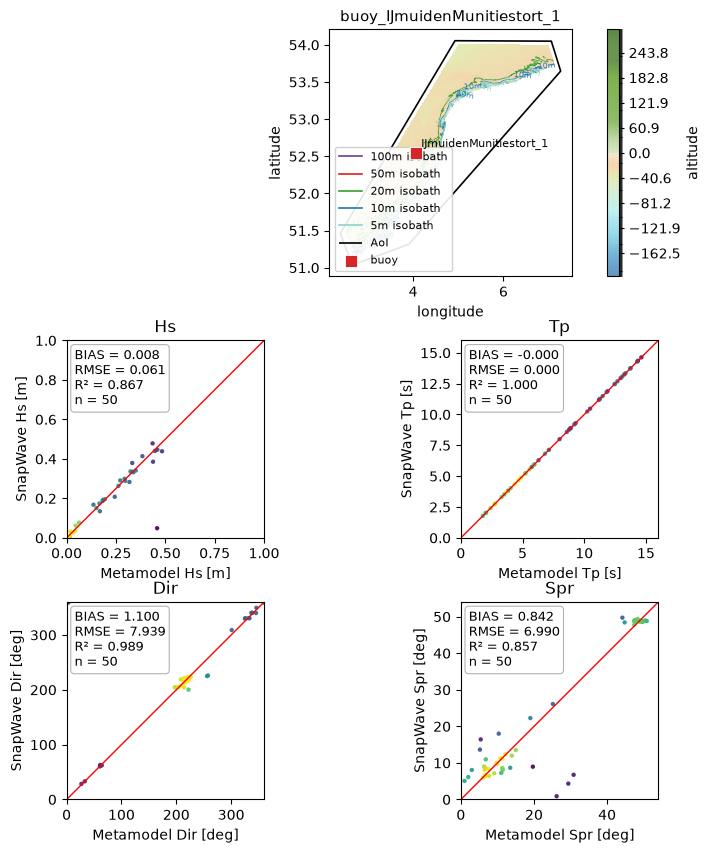

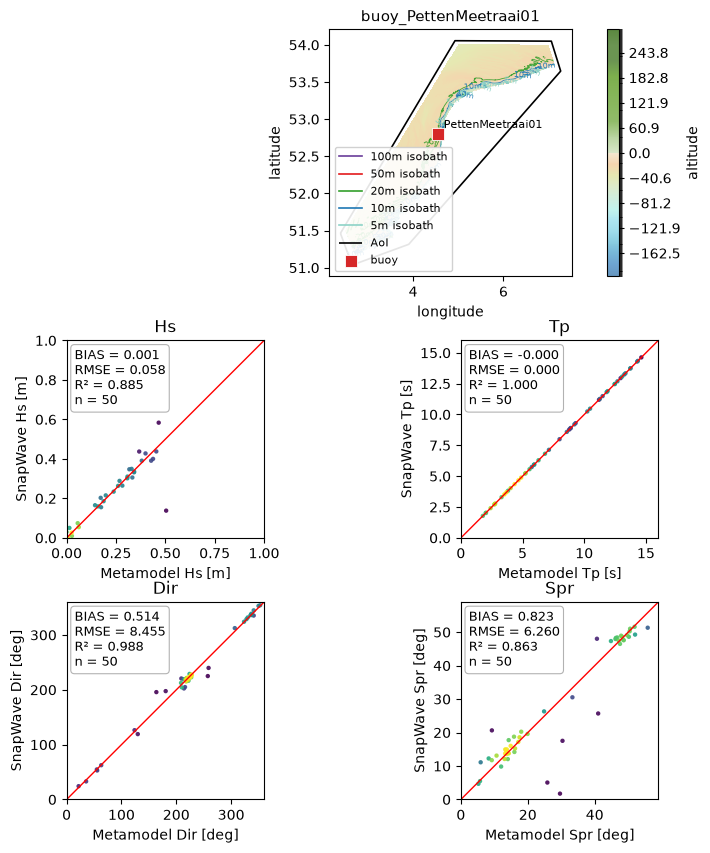

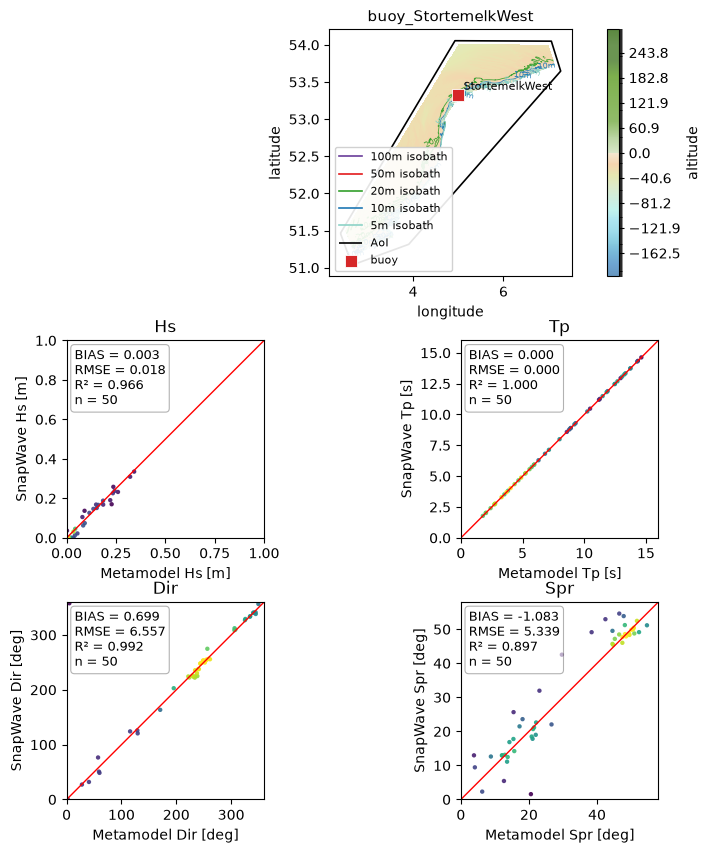

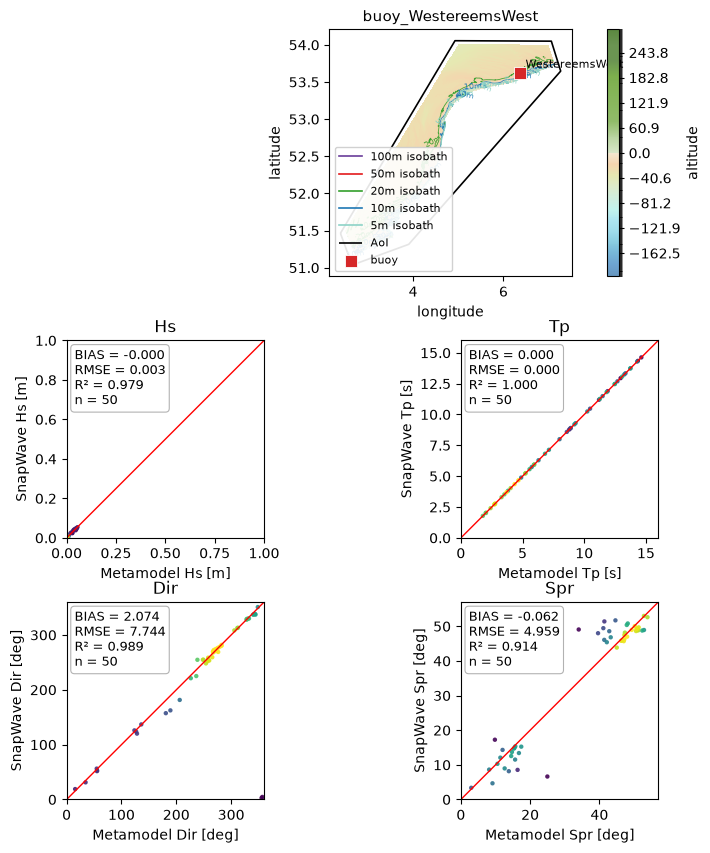

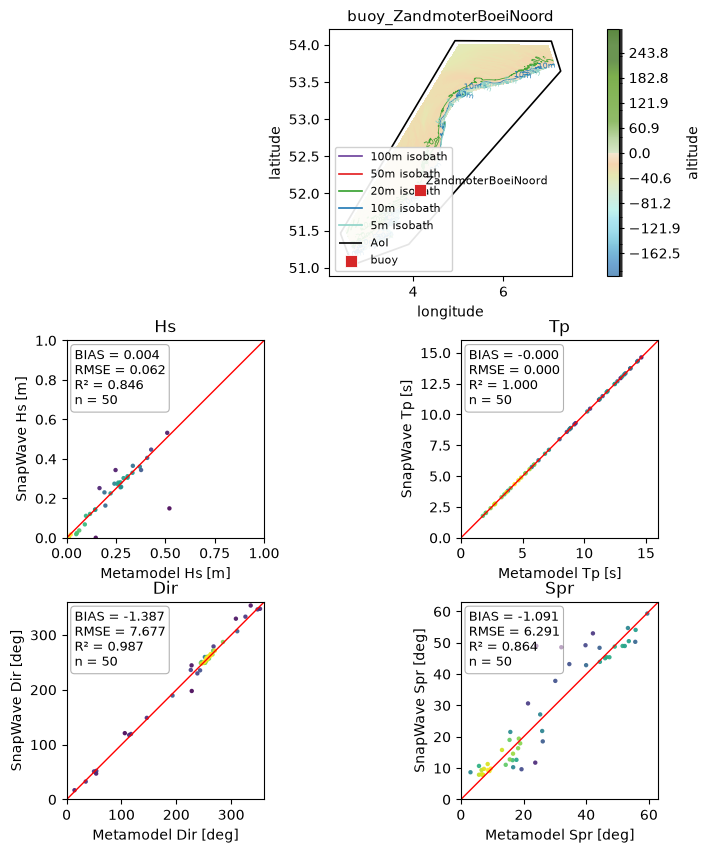

In [7]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all():
    plt.show()

## All goals

In [8]:
all_metrics = val.sweep_all()
all_metrics

,goal,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,23400,3.186683e-03,5.796408e-02,0.924301,Metamodel,SnapWave
1,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,23400,9.029724e-08,7.320748e-07,1.000000,Metamodel,SnapWave
2,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,23400,6.032070e-01,1.425964e+01,0.960195,Metamodel,SnapWave
3,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,23400,4.823733e-01,8.350126e+00,0.607965,Metamodel,SnapWave
4,1,50,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,16450,3.062621e-03,6.501875e-02,0.944575,Metamodel,SnapWave
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2395,10,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_WestereemsWest,buoy,waves,spr,Spr,50,-1.312199e+00,7.138089e+00,0.708170,Metamodel,SnapWave
2396,10,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_ZandmoterBoeiNoord,buoy,waves,hs,Hs,50,-9.970475e-04,5.847984e-03,0.924944,Metamodel,SnapWave
2397,10,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_ZandmoterBoeiNoord,buoy,waves,tp,Tp,50,-1.385017e-07,7.196446e-07,1.000000,Metamodel,SnapWave
2398,10,450,50,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_ZandmoterBoeiNoord,buoy,waves,dir,Dir,50,1.056810e+00,8.086640e+00,0.988975,Metamodel,SnapWave


In [9]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]

,goal,mda_candidate,site_label,rmse,r2,n
196,1,450,10m,0.037296,0.981342,16450
2356,10,450,10m,0.023824,0.985063,16400
436,2,450,10m,0.029857,0.987651,16300
676,3,450,10m,0.020535,0.990868,16300
916,4,450,10m,0.018315,0.992217,16300
1156,5,450,10m,0.028496,0.982717,16450
1300,6,150,10m,0.036611,0.951783,16450
1636,7,450,10m,0.028536,0.962920,16350
1876,8,450,10m,0.024207,0.978410,16400
2020,9,150,10m,0.033587,0.971574,16400
